# Налоговые паспорта субъектов РФ: примеры работы с базой

Тетрадка показывает на примерах, как устроена база налоговых паспортов ФНС России за 2014–2024 годы и как получать из неё данные: от отдельной ячейки исходного файла до временных рядов и сравнения регионов.

Справочные материалы:

- [database.md](database.md) — схема базы, таблицы и представления;
- [source-format.md](source-format.md) — содержание и формат исходных файлов;
- [catalog/](catalog/README.md) — перечень показателей по разделам и годам.

**Запуск.** Из корня репозитория:

```bash
make venv       # окружение .venv (нужен uv), если его ещё нет
make notebook   # зависимости .[notebook] и JupyterLab с этой тетрадкой
```

Пересчитать все ячейки и сохранить результаты в файл: `make notebook-run`.

Данные читаются из `data/parquet/`. Эти файлы хранятся в git, поэтому собирать базу не нужно.

**Содержание**

1. Подключение
2. Справочники: темы, территории, паспорта
3. Ячейка паспорта
4. Раздел в исходном виде
5. Поиск показателей
6. Ряд по России
7. Сравнение регионов
8. Структура поступлений и иерархия строк
9. Уровни бюджетной системы
10. Налоговая нагрузка
11. Сопоставление показателей между годами
12. Субъекты, округа и РФ
13. Нечисловые значения и единицы измерения
14. Показатели карты портала
15. Пересмотры
16. Parquet без DuckDB
17. Выгрузка результатов

## 1. Подключение

Тетрадку можно открыть из любой папки репозитория: корень определяется по папке `data/parquet/`.

Функция `connect()` создаёт базу DuckDB в памяти. Каждая таблица в ней — представление над своим файлом Parquet, а `v_value`, `v_indicator` и `v_column` создаются из [sql/views.sql](../sql/views.sql). Если база собрана командой `make build`, можно подключиться к ней: `connect(use_db=True)`. Таблицы и результаты запросов будут те же.

Функция `q()` выполняет запрос и возвращает `pandas.DataFrame`. Параметры передаются по имени и записываются в SQL как `$имя`.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "parquet").is_dir())
PARQUET = ROOT / "data" / "parquet"
DB_FILE = ROOT / "data" / "db" / "regtaxpassports.duckdb"


def connect(use_db: bool = False) -> duckdb.DuckDBPyConnection:
    """Собранная база DuckDB или представления над файлами Parquet."""
    if use_db:
        return duckdb.connect(str(DB_FILE), read_only=True)
    con = duckdb.connect()
    for path in sorted(PARQUET.glob("*.parquet")):
        con.execute(f"CREATE VIEW {path.stem} AS SELECT * FROM read_parquet('{path.as_posix()}')")
    con.execute((ROOT / "sql" / "views.sql").read_text(encoding="utf-8"))
    return con


con = connect()


def q(sql: str, **params) -> pd.DataFrame:
    """Запрос к базе; параметры записываются в SQL как $имя."""
    return con.sql(sql, params=params or None).df()

In [2]:
def num(x: float, digits: int = 0) -> str:
    """Число с разделителем разрядов: 43 471 515."""
    return f"{x:,.{digits}f}".replace(",", "\u202f")


pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", lambda x: num(x, 2))

# Категориальная палитра: цвета назначаются рядам по порядку
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
OTHER = "#a3a29c"
SURFACE = "#fcfcfb"
plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "lines.linewidth": 2,
    "font.size": 10,
})
thousands = mticker.FuncFormatter(lambda x, _: num(x))

Таблицы и число записей:

In [3]:
tables = q("SELECT table_name FROM information_schema.tables ORDER BY table_name")
tables["rows"] = [con.sql(f"SELECT count(*) FROM {name}").fetchall()[0][0] for name in tables["table_name"]]
tables

,table_name,rows
0,export,11
1,map_indicator,706
2,map_indicator_source,667
3,map_indicator_value,63915
4,passport,1032
5,passport_revision,1
6,sheet,11728
7,sheet_column,66137
8,sheet_row,439068
9,territory,99


## 2. Справочники: темы, территории, паспорта

### Темы разделов

Номер листа в паспорте не определяет содержание раздела: шаблон перестраивался в 2017 и 2023 годах. Поэтому каждому листу присвоена тема (`theme_code`). Номер темы равен номеру раздела в действующем шаблоне.

In [4]:
q("""
    SELECT theme_no, theme_code, name, portal_start_year, portal_end_year, default_unit
    FROM theme
    ORDER BY theme_no
""")

,theme_no,theme_code,name,portal_start_year,portal_end_year,default_unit
0,0,officials,"Руководители федерального округа, администрации субъекта и УФНС",<NA>,<NA>,NaN
1,1,socio_economic,Социально-экономическая характеристика,2014,<NA>,NaN
2,2,tax_base,Основные показатели налоговой базы,2014,<NA>,NaN
3,3,tax_benefits,Льготы по отдельным администрируемым доходам,2014,<NA>,млн. руб.
4,4,tax_control,Основные показатели контрольной работы,2014,<NA>,NaN
5,5,revenue_by_budget,Поступления по уровням бюджетной системы,2014,<NA>,млн. руб.
6,6,insurance_contributions,Поступления по страховым взносам,2017,<NA>,млн. руб.
7,7,revenue_by_activity,Поступления по видам экономической деятельности,2014,<NA>,млн. руб.
8,8,debt,Задолженность по налогам и сборам,2014,2022,млн. руб.
9,9,debt_by_activity,Задолженность по видам экономической деятельности,2014,2022,млн. руб.


Какой лист соответствует теме в каждом году:

In [5]:
sheets = q("""
    SELECT th.theme_no, s.theme_code, s.year, string_agg(DISTINCT s.sheet_name, ', ') AS sheet_name
    FROM sheet s
    JOIN theme th USING (theme_code)
    GROUP BY ALL
""")
sheets.pivot(index=["theme_no", "theme_code"], columns="year", values="sheet_name").sort_index().fillna("—")

,year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
theme_no,theme_code,,,,,,,,,,,
1,socio_economic,Раздел1,Раздел1,Раздел1,Раздел1,Раздел1,Раздел1,Раздел1,Раздел1,Раздел1,Раздел1,Раздел1
2,tax_base,Раздел2,Раздел2,Раздел2,Раздел2,Раздел2,Раздел2,Раздел2,Раздел2,Раздел2,Раздел2,Раздел2
3,tax_benefits,Раздел3,Раздел3,Раздел3,Раздел3,Раздел3,Раздел3,Раздел3,Раздел3,Раздел3,Раздел3,Раздел3
4,tax_control,Раздел4,Раздел4,Раздел4,Раздел4,Раздел4,Раздел4,Раздел4,Раздел4,Раздел4,Раздел4,Раздел4
5,revenue_by_budget,Раздел5,Раздел5,Раздел5,Раздел5,Раздел5,Раздел5,Раздел5,Раздел5,Раздел5,Раздел5,Раздел5
6,insurance_contributions,—,—,—,Раздел6,Раздел6,Раздел6,Раздел6,Раздел6,Раздел6,Раздел6,Раздел6
7,revenue_by_activity,Раздел6,Раздел6,Раздел6,Раздел7,Раздел7,Раздел7,Раздел7,Раздел7,Раздел7,Раздел7,Раздел7
8,debt,Раздел7,Раздел7,Раздел7,Раздел8,Раздел8,Раздел8,Раздел8,Раздел8,Раздел8,—,—
9,debt_by_activity,Раздел8,Раздел8,Раздел8,Раздел9,Раздел9,Раздел9,Раздел9,Раздел9,Раздел9,—,—


Лист «Раздел6» в 2014–2016 годах содержит поступления по видам деятельности, а с 2017 года — страховые взносы. Отбирайте разделы по `theme_code`, а не по `sheet_name`.

### Территории

`territory_code` — код территории портала: `0` — РФ, `101`…`109` — федеральные округа, `1`…`95` — субъекты (совпадает с кодом региона).

In [6]:
q("""
    SELECT kind, count(*) AS territories, min(territory_code) AS code_min, max(territory_code) AS code_max
    FROM territory
    GROUP BY kind
    ORDER BY code_min
""")

,kind,territories,code_min,code_max
0,country,1,0,0
1,region,89,1,95
2,federal_district,9,101,109


Субъект связан со своим округом полем `federal_district_code`. Субъекты Сибирского федерального округа:

In [7]:
q("""
    SELECT r.territory_code, r.name, fd.name AS federal_district
    FROM territory r
    JOIN territory fd ON fd.territory_code = r.federal_district_code
    WHERE fd.territory_code = 106
    ORDER BY r.name
""")

,territory_code,name,federal_district
0,22,Алтайский край,СИБИРСКИЙ ФЕДЕРАЛЬНЫЙ ОКРУГ
1,38,Иркутская область,СИБИРСКИЙ ФЕДЕРАЛЬНЫЙ ОКРУГ
2,42,Кемеровская область,СИБИРСКИЙ ФЕДЕРАЛЬНЫЙ ОКРУГ
3,24,Красноярский край,СИБИРСКИЙ ФЕДЕРАЛЬНЫЙ ОКРУГ
4,54,Новосибирская область,СИБИРСКИЙ ФЕДЕРАЛЬНЫЙ ОКРУГ
5,55,Омская область,СИБИРСКИЙ ФЕДЕРАЛЬНЫЙ ОКРУГ
6,4,Республика Алтай,СИБИРСКИЙ ФЕДЕРАЛЬНЫЙ ОКРУГ
7,17,Республика Тыва,СИБИРСКИЙ ФЕДЕРАЛЬНЫЙ ОКРУГ
8,19,Республика Хакасия,СИБИРСКИЙ ФЕДЕРАЛЬНЫЙ ОКРУГ
9,70,Томская область,СИБИРСКИЙ ФЕДЕРАЛЬНЫЙ ОКРУГ


Территории без паспортов: новые субъекты (`passport_from_year = 2027`) и их округ.

In [8]:
q("""
    SELECT territory_code, kind, name, passport_from_year
    FROM territory
    WHERE territory_code NOT IN (SELECT territory_code FROM passport)
    ORDER BY territory_code
""")

,territory_code,kind,name,passport_from_year
0,90,region,Запорожская область,2027
1,93,region,Донецкая Народная Республика,2027
2,94,region,Луганская Народная Республика,2027
3,95,region,Херсонская область,2027
4,109,federal_district,ЮГО-ЗАПАДНЫЕ СУБЪЕКТЫ РФ,2027


### Паспорта

Паспорт за год Y составлен по состоянию на 01.01.Y+1.

In [9]:
q("""
    SELECT p.year,
           min(p.as_of_date) AS as_of_date,
           count(*) FILTER (WHERE t.kind = 'region') AS regions,
           count(*) FILTER (WHERE t.kind = 'federal_district') AS districts,
           count(*) FILTER (WHERE t.kind = 'country') AS country,
           count(*) AS total
    FROM passport p
    JOIN territory t USING (territory_code)
    GROUP BY p.year
    ORDER BY p.year
""")

,year,as_of_date,regions,districts,country,total
0,2014,2015-01-01,83,8,1,92
1,2015,2016-01-01,85,8,1,94
2,2016,2017-01-01,85,8,1,94
3,2017,2018-01-01,85,8,1,94
4,2018,2019-01-01,85,8,1,94
5,2019,2020-01-01,85,8,1,94
6,2020,2021-01-01,85,8,1,94
7,2021,2022-01-01,85,8,1,94
8,2022,2023-01-01,85,8,1,94
9,2023,2024-01-01,85,8,1,94


В 2014 году паспортов субъектов 83: Республики Крым и г. Севастополя ещё нет. Учитывайте это, сравнивая суммы по субъектам за разные годы.

## 3. Ячейка паспорта

Каждое значение в базе — ячейка Excel с адресом `(year, territory_code, sheet_name, row_no, col_no)`. Представление `v_value` добавляет к ней название территории, тему, наименование строки, шапку графы и единицу измерения.

Пример — валовой региональный продукт Томской области (код 70) в паспорте 2024 года: раздел 1, код строки 101.

In [10]:
q("""
    SELECT year, territory, sheet_name, row_no, col_no, row_code, label, column_header, value, unit, unit_source
    FROM v_value
    WHERE year = 2024 AND territory_code = 70 AND theme_code = 'socio_economic' AND row_code = '101'
    ORDER BY col_no
""")

,year,territory,sheet_name,row_no,col_no,row_code,label,column_header,value,unit,unit_source
0,2024,Томская область,Раздел1,9,3,101,ВАЛОВОЙ РЕГИОНАЛЬНЫЙ ПРОДУКТ (по состоянию на 01.01.2024) (млрд. руб.),2024 год,912.45,млрд. руб.,row
1,2024,Томская область,Раздел1,9,4,101,ВАЛОВОЙ РЕГИОНАЛЬНЫЙ ПРОДУКТ (по состоянию на 01.01.2024) (млрд. руб.),В % к предыдущему году,112.21,%,column


Графа 3 — значение, графа 4 — «В % к предыдущему году». У одной строки бывают значения в разных единицах, поэтому фильтр по `col_no` нужен почти всегда.

`row_no` и `col_no` указывают на ячейку исходного файла. Имя файла и реквизиты титульного листа хранятся в таблице `passport`:

In [11]:
q("""
    SELECT file_name, file_sha256, as_of_date, doc_title, admin_center, federal_district_label, title_code
    FROM passport
    WHERE year = 2024 AND territory_code = 70
""").T

,0
file_name,НП_2024_Томская область.xls
file_sha256,12ffe99dbe86eaf6a51237cd96d2df1bc38f34ae218e70404970b54553d03e9b
as_of_date,2025-01-01 00:00:00
doc_title,НАЛОГОВЫЙ ПАСПОРТ СУБЪЕКТА РОССИЙСКОЙ ФЕДЕРАЦИИ
admin_center,г. Томск
federal_district_label,СИБИРСКИЙ ФЕДЕРАЛЬНЫЙ ОКРУГ
title_code,7000


Разделы этого паспорта. `section_unit` — единица, указанная надписью над таблицей; в поздних годах её обычно нет.

In [12]:
q("""
    SELECT sheet_name, theme_code, title, section_unit, header_row_no
    FROM sheet
    WHERE year = 2024 AND territory_code = 70
    ORDER BY sheet_no
""")

,sheet_name,theme_code,title,section_unit,header_row_no
0,Раздел1,socio_economic,Раздел 1.Социально-экономическая характеристика региона,None,7
1,Раздел2,tax_base,Раздел 2.Основные показатели налоговой базы по администрируемым доходам,None,4
2,Раздел3,tax_benefits,Раздел 3.Льготы по отдельным администрируемым доходам,None,4
3,Раздел4,tax_control,Раздел 4.Основные показатели контрольной работы налоговых органов,None,4
4,Раздел5,revenue_by_budget,Раздел 5.Поступления основных администрируемых доходов в структуре консолидированного ...,None,4
5,Раздел6,insurance_contributions,Раздел 6.Поступление доходов по страховым взносам на обязательное социальное страхован...,None,4
6,Раздел7,revenue_by_activity,Раздел 7.Поступления администрируемых доходов в консолидированный бюджет Российской Фе...,None,4
7,Раздел10,tax_burden,Раздел 10.Показатели налоговой нагрузки,None,4
8,Раздел11,tax_burden_by_activity,Раздел 11.Показатели налоговой нагрузки по отдельным видам экономической деятельности ...,None,4
9,Раздел12,forecast,Раздел 12.Оценка и прогнозирование поступлений отдельных налогов,None,4


## 4. Раздел в исходном виде

Таблицы `sheet_row`, `sheet_column` и `value` хранят лист без потерь, поэтому его можно собрать обратно. Функция `sheet_table()` разворачивает значения в таблицу «показатель × графа»; отступ наименования соответствует уровню вложенности (`level`). Функция `sheet_columns()` выводит шапку раздела.

In [13]:
def sheet_table(year: int, territory_code: int, theme_code: str, include_hidden: bool = False) -> pd.DataFrame:
    """Раздел паспорта как в файле: строки — показатели, столбцы — номера граф."""
    cells = q("""
        SELECT row_no, row_code, level, label, col_no, value
        FROM v_value
        WHERE year = $year AND territory_code = $territory AND theme_code = $theme
          AND (NOT is_hidden OR $include_hidden)
    """, year=year, territory=territory_code, theme=theme_code, include_hidden=include_hidden)
    cells["label"] = ["\u00a0" * 4 * level + label for level, label in zip(cells["level"], cells["label"])]
    return cells.pivot(index=["row_no", "row_code", "label"], columns="col_no", values="value")


def sheet_columns(year: int, territory_code: int, theme_code: str) -> pd.DataFrame:
    """Шапка раздела: номер графы, уровни шапки через « → », единица."""
    return q("""
        SELECT c.col_no, c.header, c.unit
        FROM sheet_column c
        JOIN sheet s USING (year, territory_code, sheet_name)
        WHERE c.year = $year AND c.territory_code = $territory AND s.theme_code = $theme
        ORDER BY c.col_no
    """, year=year, territory=territory_code, theme=theme_code)


sheet_columns(2024, 70, "revenue_by_budget")

,col_no,header,unit
0,3,Поступило в консолидированный бюджет Российской Федерации → Всего,NaN
1,4,Поступило в консолидированный бюджет Российской Федерации → В % к предыдущему периоду,%
2,5,Поступило в консолидированный бюджет Российской Федерации → Удельный вес (%),%
3,6,в том числе: → В федеральный бюджет → Всего,NaN
4,7,в том числе: → В федеральный бюджет → В % к предыдущему периоду,%
5,8,в том числе: → В федеральный бюджет → Удельный вес (%),%
6,9,в том числе: → В консолидированный бюджет субъекта РФ → Всего,NaN
7,10,в том числе: → В консолидированный бюджет субъекта РФ → В % к предыдущему периоду,%
8,11,в том числе: → В консолидированный бюджет субъекта РФ → Удельный вес (%),%
9,12,в том числе: → из него: → В местный бюджет → Всего,NaN


Раздел 5 Томской области за 2024 год, млн руб.: всего (графа 3), в федеральный бюджет (6), в консолидированный бюджет субъекта (9) и в местные бюджеты (12). `NaN` — ячейка с текстом `X` («не заполняется»).

In [14]:
sheet_table(2024, 70, "revenue_by_budget")[[3, 6, 9, 12]]

,,col_no,3,6,9,12
row_no,row_code,label,,,,
9,501,ВСЕГО ПО АДМИНИСТРИРУЕМЫМ ДОХОДАМ,413 862.96,330 137.04,83 725.92,17 190.17
10,502,Налог на прибыль организации,19 289.01,2 547.86,16 741.15,0.00
11,503,Налог на доходы физических лиц,42 654.63,858.88,41 795.75,12 434.51
12,504,"Налог на добавленную стоимость на товары, реализуемые на территории РФ",89 382.02,89 382.02,NaN,NaN
13,505,"Налог на добавленную стоимость на товары, ввозимые на территорию Российской Федерации",496.62,496.62,NaN,NaN
14,506,"Акцизы по подакцизным товарам (продукции), производимым на территории РФ",1 073.96,-5 039.16,6 113.13,0.00
16,507,на спирт этиловый из всех видов сырья и спиртосодержащую продукцию,17.10,0.00,17.10,0.00
17,508,на табачную продукцию,0.78,0.78,NaN,NaN
18,509,на нефтепродукты,583.50,146.46,437.04,0.00


Кроме показателей, в листе есть заголовки групп (`kind = 'heading'`) и связки «в том числе:», «из них:» (`kind = 'qualifier'`). У них нет кода строки и значений. Родитель показателя задан полем `parent_code`. Начало раздела льгот:

In [15]:
q("""
    SELECT r.row_no, r.row_code, r.kind, r.level, r.parent_code, r.label
    FROM sheet_row r
    JOIN sheet s USING (year, territory_code, sheet_name)
    WHERE r.year = 2024 AND r.territory_code = 70 AND s.theme_code = 'tax_benefits'
    ORDER BY r.row_no
    LIMIT 14
""")

,row_no,row_code,kind,level,parent_code,label
0,6,NaN,heading,0,NaN,"СУММА НАЛОГА, НЕ ПОСТУПИВШАЯ В БЮДЖЕТ:"
1,7,301,indicator,1,NaN,ПО НАЛОГУ НА ПРИБЫЛЬ ОРГАНИЗАЦИЙ
2,8,NaN,qualifier,2,NaN,из них:
3,9,302,indicator,3,301,В связи с установлением законодательными (представительными) органами субъектов Россий...
4,10,303,indicator,1,NaN,ПО НАЛОГУ НА ИМУЩЕСТВО ОРГАНИЗАЦИЙ
5,11,NaN,qualifier,2,NaN,в том числе:
6,12,304,indicator,3,303,"По льготам, установленным ст. 372.1, 381, 382, 385.1 НК РФ, по льготам, предоставляемы..."
7,13,305,indicator,3,303,"По льготам,установленным в соответствии с п.2 ст.372 НК РФ органами законодательной вл..."
8,14,306,indicator,1,NaN,ПО ЗЕМЕЛЬНОМУ НАЛОГУ
9,15,NaN,qualifier,2,NaN,в том числе


## 5. Поиск показателей

Коды строк и номера граф удобно искать в каталоге ([catalog/](catalog/README.md)) или в представлениях `v_indicator` и `v_column`. Представления описывают шаблон года: какие показатели и графы есть в теме и как они названы у большинства паспортов.

In [16]:
def find_indicator(text: str, year: int = 2024) -> pd.DataFrame:
    """Показатели года, в наименовании которых есть текст (без учёта регистра)."""
    return q("""
        SELECT theme_code, sheet_name, row_code, label, unit, parent_code, passports
        FROM v_indicator
        WHERE year = $year AND label ILIKE '%' || $text || '%'
        ORDER BY theme_code, try_cast(row_code AS DOUBLE)
    """, year=year, text=text)


find_indicator("имуществ")

,theme_code,sheet_name,row_code,label,unit,parent_code,passports
0,revenue_by_activity,Раздел7,726,Деятельность по операциям с недвижимым имуществом,NaN,701,94
1,revenue_by_budget,Раздел5,513,Налоги на имущество,NaN,501,94
2,revenue_by_budget,Раздел5,514,Налог на имущество физических лиц,NaN,513,94
3,revenue_by_budget,Раздел5,515,Налог на имущество организаций,NaN,513,94
4,tax_base,Раздел2,212,"сумма налога, исчисленная при реализации (передаче для собственных нужд) товаров (рабо...",млн. руб.,210,94
5,tax_base,Раздел2,247,Среднегодовая стоимость имущества за налоговый период (млн. руб.),млн. руб.,NaN,94
6,tax_base,Раздел2,250,среднегодовая стоимость имущества (млн. руб.),млн. руб.,249,94
7,tax_benefits,Раздел3,303,ПО НАЛОГУ НА ИМУЩЕСТВО ОРГАНИЗАЦИЙ,NaN,NaN,94
8,tax_benefits,Раздел3,314,ПО НАЛОГУ НА ИМУЩЕСТВО ФИЗИЧЕСКИХ ЛИЦ,NaN,NaN,94
9,tax_burden,Раздел10,1009,Налог на имущество организации,NaN,1001,94


Графы раздела «Поступления по видам экономической деятельности» в 2024 году. Уровни многоуровневой шапки соединены через « → »:

In [17]:
q("""
    SELECT col_no, header, unit, passports, header_variants
    FROM v_column
    WHERE year = 2024 AND theme_code = 'revenue_by_activity'
    ORDER BY col_no
""")

,col_no,header,unit,passports,header_variants
0,3,"Поступило в консолидированный бюджет, всего",NaN,94,1
1,4,Уд. вес в общей сумме поступлений (%),%,94,1
2,5,в том числе → Федеральные налоги,NaN,94,1
3,6,в том числе → из них → налог на прибыль организации → Всего,NaN,94,1
4,7,в том числе → из них → налог на прибыль организации → в том числе в федеральный бюджет,NaN,94,1
5,8,в том числе → из них → налог на доходы физических лиц,NaN,94,1
6,9,в том числе → из них → НДС,NaN,94,1
7,10,в том числе → из них → акцизы по подакцизным товарам,NaN,94,1
8,11,в том числе → из них → налог на добычу полезных ископаемых,NaN,94,1
9,12,в том числе → из них → остальные налоги и сборы,NaN,94,1


`label_variants > 1` означает, что наименование строки различается между паспортами одного года:

In [18]:
q("""
    SELECT theme_code, row_code, label, label_variants, passports
    FROM v_indicator
    WHERE year = 2024 AND label_variants > 1
    ORDER BY label_variants DESC, theme_code, row_code
    LIMIT 10
""")

,theme_code,row_code,label,label_variants,passports
0,socio_economic,146,КОЛИЧЕСТВО СУБЪЕКТОВ МАЛОГО И СРЕДНЕГО ПРЕДПРИНИМАТЕЛЬСТВА на 10.01.2024 г. (единиц),3,94
1,revenue_by_budget,-501,Для расчёта процентов к 2008 году по остальн. налогам,2,94
2,socio_economic,101,ВАЛОВОЙ РЕГИОНАЛЬНЫЙ ПРОДУКТ (по состоянию на 01.01.2024) (млрд. руб.),2,94
3,socio_economic,102,ИНДЕКС ФИЗИЧЕСКОГО ОБЪЕМА ВРП (по состоянию на 01.01.2024) (%),2,94
4,socio_economic,110,"ОБЪЕМ ОТГРУЖЕННЫХ ТОВАРОВ СОБСТВЕННОГО ПРОИЗВОДСТВА, ВЫПОЛНЕННЫХ РАБОТ И УСЛУГ СОБСТВЕ...",2,94
5,socio_economic,115,ВНЕШНЕТОРГОВЫЙ ОБОРОТ (млн. долларов США),2,94
6,socio_economic,116,экспорт товаров (млн. долларов США),2,94
7,socio_economic,117,импорт товаров (млн. долларов США),2,94
8,socio_economic,119,ВНЕШНЕТОРГОВЫЙ ОБОРОТ (млн. руб.),2,94
9,socio_economic,120,экспорт товаров (млн. руб.),2,94


Например, в паспорте РФ строка 101 — это ВВП, а у округов и субъектов — ВРП:

In [19]:
q("""
    SELECT r.label, list(DISTINCT t.kind ORDER BY t.kind) AS kinds, count(*) AS passports
    FROM sheet_row r
    JOIN sheet s USING (year, territory_code, sheet_name)
    JOIN territory t USING (territory_code)
    WHERE r.year = 2024 AND s.theme_code = 'socio_economic' AND r.row_code = '101'
    GROUP BY r.label
    ORDER BY passports DESC
""")

,label,kinds,passports
0,ВАЛОВОЙ РЕГИОНАЛЬНЫЙ ПРОДУКТ (по состоянию на 01.01.2024) (млрд. руб.),"[federal_district, region]",93
1,ВАЛОВОЙ ВНУТРЕННИЙ ПРОДУКТ (млрд. руб.),[country],1


## 6. Ряд по России

Поступления администрируемых доходов в консолидированный бюджет РФ (раздел 5, строка 501, графа 3) и налоговая нагрузка (раздел 10, графа 3). Код итоговой строки 501 одинаков во всех годах. У налоговой нагрузки код менялся (901 → 1001), поэтому она отбирается по `label_key` (см. раздел 11 тетрадки).

In [20]:
rf = q("""
    SELECT year,
           max(value) FILTER (WHERE theme_code = 'revenue_by_budget' AND row_code = '501') / 1e6 AS revenue_trln,
           max(value) FILTER (WHERE theme_code = 'tax_burden' AND label_key = 'по администрируемым доходам')
               AS tax_burden_pct
    FROM v_value
    WHERE territory_code = 0 AND col_no = 3
    GROUP BY year
    ORDER BY year
""").set_index("year")
rf

,revenue_trln,tax_burden_pct
year,,
2014,12.67,23.42
2015,13.79,23.41
2016,14.48,22.28
2017,17.34,20.13
2018,21.33,20.53
2019,22.74,26.76
2020,21.01,22.16
2021,28.53,30.41
2022,33.58,27.71


Две величины в разных единицах — два графика, а не две оси на одном.

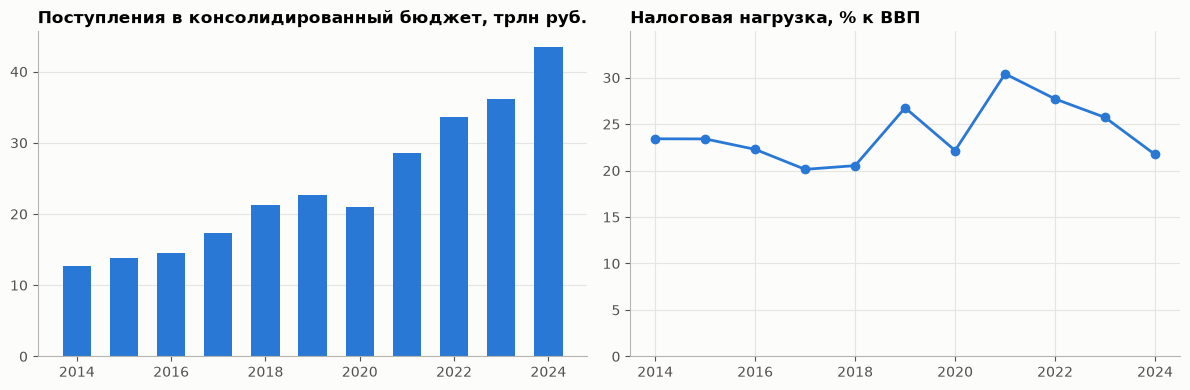

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.bar(rf.index, rf["revenue_trln"], width=0.6)
ax1.set_title("Поступления в консолидированный бюджет, трлн руб.")
ax2.plot(rf.index, rf["tax_burden_pct"], marker="o", markersize=6)
ax2.set_title("Налоговая нагрузка, % к ВВП")
ax2.set_ylim(0, rf["tax_burden_pct"].max() * 1.15)
for ax in (ax1, ax2):
    ax.xaxis.set_major_locator(mticker.MultipleLocator(2))
ax1.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

Налоговую нагрузку шаблон паспорта считает сам: поступления делятся на ВРП (ВВП) из скрытой строки раздела нагрузки (код -901 или -1001). Пересчитаем её и сравним эту строку с ВВП из раздела 1:

In [22]:
check = q("""
    SELECT year,
           max(value) FILTER (WHERE theme_code = 'revenue_by_budget' AND row_code = '501') / 1e3 AS revenue_bln,
           max(value) FILTER (WHERE theme_code = 'tax_burden' AND row_code IN ('-901', '-1001')) AS gdp_hidden_row,
           max(value) FILTER (WHERE theme_code = 'socio_economic' AND row_code = '101') AS gdp_section1,
           max(label) FILTER (WHERE theme_code = 'socio_economic' AND row_code = '101') AS gdp_label,
           max(value) FILTER (WHERE theme_code = 'tax_burden' AND label_key = 'по администрируемым доходам')
               AS tax_burden_pct
    FROM v_value
    WHERE territory_code = 0 AND col_no = 3
    GROUP BY year
    ORDER BY year
""")
check["recalc_pct"] = check["revenue_bln"] / check["gdp_hidden_row"] * 100
check

,year,revenue_bln,gdp_hidden_row,gdp_section1,gdp_label,tax_burden_pct,recalc_pct
0,2014,12 670.19,54 103.00,54 103.00,ВАЛОВОЙ ВНУТРЕННИЙ ПРОДУКТ (по состоянию на 01.01.2014) (млрд. руб.),23.42,23.42
1,2015,13 788.30,58 900.65,58 900.65,ВАЛОВОЙ ВНУТРЕННИЙ ПРОДУКТ (по состоянию на 01.01.2015) (млрд. руб.),23.41,23.41
2,2016,14 482.88,64 997.04,64 997.04,ВАЛОВОЙ ВНУТРЕННИЙ ПРОДУКТ (по состоянию на 01.01.2016) (млрд. руб.),22.28,22.28
3,2017,17 343.44,86 148.60,86 148.60,ВАЛОВОЙ ВНУТРЕННИЙ ПРОДУКТ (по состоянию на 01.01.2017) (млрд. руб.),20.13,20.13
4,2018,21 328.50,103 875.80,103 875.80,ВАЛОВОЙ ВНУТРЕННИЙ ПРОДУКТ (по состоянию на 01.01.2019) (млрд. руб.),20.53,20.53
5,2019,22 737.27,84 976.70,84 976.70,ВАЛОВОЙ ВНУТРЕННИЙ ПРОДУКТ (по состоянию на 01.01.2020) (млрд. руб.),26.76,26.76
6,2020,21 014.24,94 831.10,94 831.10,ВАЛОВОЙ ВНУТРЕННИЙ ПРОДУКТ (по состоянию на 01.01.2021) (млрд. руб.),22.16,22.16
7,2021,28 530.95,93 810.30,93 810.30,ВАЛОВОЙ ВНУТРЕННИЙ ПРОДУКТ (по состоянию на 01.01.2021) (млрд. руб.),30.41,30.41
8,2022,33 582.26,121 182.99,121 182.99,ВАЛОВОЙ ВНУТРЕННИЙ ПРОДУКТ (по состоянию на 01.01.2022) (млрд. руб.),27.71,27.71
9,2023,36 182.87,140 670.82,176 413.59,ВАЛОВОЙ ВНУТРЕННИЙ ПРОДУКТ (млрд. руб.),25.72,25.72


Что видно из таблицы:

- нагрузка точно равна поступлениям, делённым на значение скрытой строки;
- ВВП в разделе 1 паспорта РФ дан «по состоянию на» дату из наименования строки. Ряд неоднороден: 103,9 трлн руб. в паспорте 2018 года и 85,0 трлн руб. в паспорте 2019 года;
- в 2023 году ВВП в разделе 1 пересмотрен (см. раздел 15 тетрадки), а скрытая строка и нагрузка остались прежними. Поэтому 36,2 / 176,4 ≠ 25,7 %;
- в 2024 году значения в скрытой строке и в разделе 1 тоже немного различаются: 200 039,5 и 201 152,1 млрд руб.

Прежде чем строить ряд, читайте наименование строки: период показателя может не совпадать с годом паспорта. Для макроэкономического анализа берите ВВП из первоисточника — Росстата.

## 7. Сравнение регионов

Поступления администрируемых доходов по субъектам за 2024 год, млрд руб. Доля считается от суммы по субъектам.

In [23]:
regions_2024 = q("""
    SELECT territory_code, territory, value / 1e3 AS revenue_bln
    FROM v_value
    WHERE year = 2024 AND theme_code = 'revenue_by_budget' AND row_code = '501' AND col_no = 3
      AND territory_kind = 'region'
    ORDER BY value DESC
""")
regions_2024["share_pct"] = regions_2024["revenue_bln"] / regions_2024["revenue_bln"].sum() * 100
regions_2024["cum_share_pct"] = regions_2024["share_pct"].cumsum()
regions_2024.head(15)

,territory_code,territory,revenue_bln,share_pct,cum_share_pct
0,77,г. Москва,8 358.17,19.33,19.33
1,86,Ханты-Мансийский АО-Югра,5 093.24,11.78,31.11
2,89,Ямало-Ненецкий АО,3 318.23,7.67,38.78
3,78,г. Санкт-Петербург,2 411.09,5.58,44.36
4,50,Московская область,2 234.42,5.17,49.53
5,16,Республика Татарстан,1 595.46,3.69,53.22
6,59,Пермский край,1 453.33,3.36,56.58
7,63,Самарская область,1 333.44,3.08,59.66
8,24,Красноярский край,964.78,2.23,61.90
9,56,Оренбургская область,889.60,2.06,63.95


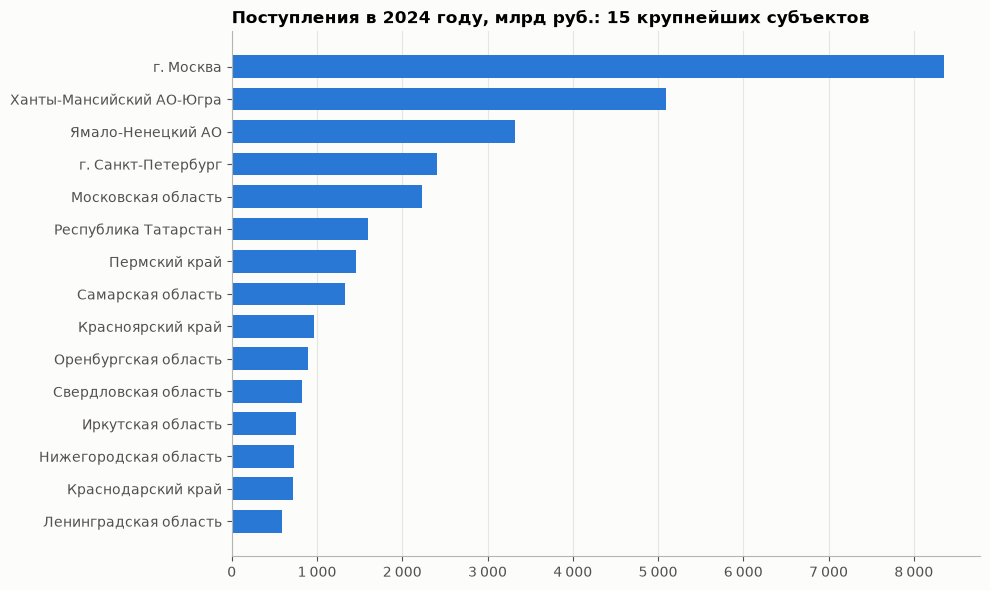

In [24]:
top = regions_2024.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top["territory"], top["revenue_bln"], height=0.7)
ax.set_title("Поступления в 2024 году, млрд руб.: 15 крупнейших субъектов")
ax.xaxis.set_major_formatter(thousands)
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

### Поступления на душу населения

Численность населения — раздел 1, `label_key = 'численность населения'`, тыс. чел. Поступления в млн руб., делённые на численность в тыс. чел., дают тыс. руб. на человека.

In [25]:
per_capita = q("""
    WITH revenue AS (
        SELECT territory_code, territory, value AS revenue_mln
        FROM v_value
        WHERE year = 2024 AND theme_code = 'revenue_by_budget' AND row_code = '501' AND col_no = 3
          AND territory_kind = 'region'
    ), population AS (
        SELECT territory_code, value AS population_ths
        FROM v_value
        WHERE year = 2024 AND theme_code = 'socio_economic' AND label_key = 'численность населения' AND col_no = 3
    )
    SELECT territory, revenue_mln, population_ths, revenue_mln / population_ths AS revenue_ths_rub_per_capita
    FROM revenue
    JOIN population USING (territory_code)
    ORDER BY revenue_ths_rub_per_capita DESC
""")
pd.concat([per_capita.head(8), per_capita.tail(8)])

,territory,revenue_mln,population_ths,revenue_ths_rub_per_capita
0,Ямало-Ненецкий АО,3 318 229.89,515.96,6 431.18
1,Ненецкий АО,139 416.27,42.22,3 301.83
2,Ханты-Мансийский АО-Югра,5 093 242.66,1 759.39,2 894.90
3,Сахалинская область,410 046.01,457.59,896.10
4,г. Москва,8 358 166.21,13 149.80,635.61
5,Пермский край,1 453 328.74,2 495.27,582.43
6,Оренбургская область,889 603.70,1 828.66,486.48
7,г. Санкт-Петербург,2 411 089.08,5 597.76,430.72
77,Республика Алтай,11 129.30,210.77,52.80
78,Республика Северная Осетия-Алания,33 369.65,678.88,49.15


## 8. Структура поступлений и иерархия строк

Итоги и детализация лежат в одной таблице. Непосредственные составляющие итога — строки, у которых `parent_code` равен коду итоговой строки. Структура поступлений в консолидированный бюджет РФ за 2024 год:

In [26]:
structure = q("""
    SELECT c.row_code, c.label, c.value AS revenue_mln, c.value / p.value * 100 AS share_pct
    FROM v_value c
    JOIN v_value p
      ON p.year = c.year AND p.territory_code = c.territory_code AND p.sheet_name = c.sheet_name
     AND p.col_no = c.col_no AND p.row_code = c.parent_code
    WHERE c.year = 2024 AND c.territory_code = 0 AND c.theme_code = 'revenue_by_budget' AND c.col_no = 3
      AND c.parent_code = '501'
    ORDER BY c.value DESC
""")
structure

,row_code,label,revenue_mln,share_pct
0,520,Налог на добычу полезных ископаемых,12 640 372.36,29.08
1,504,"Налог на добавленную стоимость на товары, реализуемые на территории РФ",8 733 632.61,20.09
2,503,Налог на доходы физических лиц,8 372 341.61,19.26
3,502,Налог на прибыль организации,8 051 672.19,18.52
4,513,Налоги на имущество,1 842 996.04,4.24
5,527,"Налог, взимаемый в связи с применением упрощенной системы налогообложения",1 316 422.46,3.03
6,505,"Налог на добавленную стоимость на товары, ввозимые на территорию Российской Федерации",662 915.70,1.52
7,531,Утилизационный сбор в федеральный бюджет,417 074.87,0.96
8,530.1,Налог на профессиональный доход,59 791.09,0.14
9,530,"Налог, взимаемый в связи с применением патентной системы налогообложения",45 701.90,0.11


Детализация неполная, и в ней бывают отрицательные значения (возвраты НДС и акцизов). Поэтому сумма составляющих не совпадает с итогом:

In [27]:
total = q("""
    SELECT value FROM v_value
    WHERE year = 2024 AND territory_code = 0 AND theme_code = 'revenue_by_budget' AND row_code = '501' AND col_no = 3
""")["value"].iloc[0]
print(f"Итог, строка 501:       {num(total):>12} млн руб.")
print(f"Сумма составляющих:     {num(structure['revenue_mln'].sum()):>12} млн руб.")
print(f"Не вошло в детализацию: {num(total - structure['revenue_mln'].sum()):>12} млн руб.")

Итог, строка 501:         43 471 515 млн руб.
Сумма составляющих:       41 112 938 млн руб.
Не вошло в детализацию:    2 358 577 млн руб.


### Динамика структуры

Чтобы построить ряд по налогам, коды строк брать нельзя: в 2014 году шаблон раздела 5 был другим. Строка 520 в 2014 году — газовый конденсат, а НДПИ стоит в строке 517:

In [28]:
q("""
    SELECT row_code, year, label
    FROM v_indicator
    WHERE theme_code = 'revenue_by_budget' AND row_code IN ('517', '520') AND year IN (2014, 2015)
    ORDER BY row_code, year
""")

,row_code,year,label
0,517,2014,Налог на добычу полезных ископаемых
1,517,2015,транспортный налог с организаций
2,520,2014,газовый конденсат из всех видов месторождений углеводородного сырья
3,520,2015,Налог на добычу полезных ископаемых


Поэтому налоги отбираются по началу `label_key` среди непосредственных составляющих итога 501. Наименования тоже менялись: «единый налог, взимаемый в связи с применением упрощенной системы…» до 2017 года и «налог, взимаемый…» с 2018 года. Остаток «Прочие» — итог минус выделенные налоги; в него входят акцизы, которые в 2024 году отрицательны.

In [29]:
MAIN_TAXES = {
    "налог на прибыль": "Налог на прибыль",
    "налог на доходы физических лиц": "НДФЛ",
    "налог на добавленную стоимость на товары реализуемые": "НДС (внутренний)",
    "налог на добычу полезных ископаемых": "НДПИ",
    "единый налог взимаемый в связи с применением упрощенной": "УСН",
    "налог взимаемый в связи с применением упрощенной": "УСН",
}
budget_rows = q("""
    SELECT year, row_code, label_key, value / 1e6 AS trln
    FROM v_value
    WHERE territory_code = 0 AND theme_code = 'revenue_by_budget' AND col_no = 3
      AND (row_code = '501' OR parent_code = '501')
""")
budget_rows["tax"] = budget_rows["label_key"].map(
    lambda key: next((name for prefix, name in MAIN_TAXES.items() if key.startswith(prefix)), None))
budget_rows.loc[budget_rows["row_code"] == "501", "tax"] = "Всего"

# pivot без агрегирования: если налог найдётся дважды за год, будет ошибка
rf_taxes = budget_rows.dropna(subset=["tax"]).pivot(index="year", columns="tax", values="trln")
names = list(dict.fromkeys(MAIN_TAXES.values()))
parts = rf_taxes[names].copy()
parts["Прочие"] = rf_taxes["Всего"] - rf_taxes[names].sum(axis=1)
parts

tax,Налог на прибыль,НДФЛ,НДС (внутренний),НДПИ,УСН,Прочие
year,,,,,,
2014,2.37,2.69,2.18,2.90,0.23,2.29
2015,2.60,2.81,2.45,3.23,0.25,2.45
2016,2.77,3.02,2.66,2.93,0.29,2.82
2017,3.29,3.25,3.07,4.13,0.35,3.26
2018,4.10,3.65,3.57,6.13,0.42,3.45
2019,4.54,3.96,4.26,6.11,0.49,3.38
2020,4.02,4.25,4.27,3.95,0.50,4.02
2021,6.08,4.88,5.48,7.34,0.72,4.03
2022,6.36,5.73,6.49,10.97,0.88,3.15


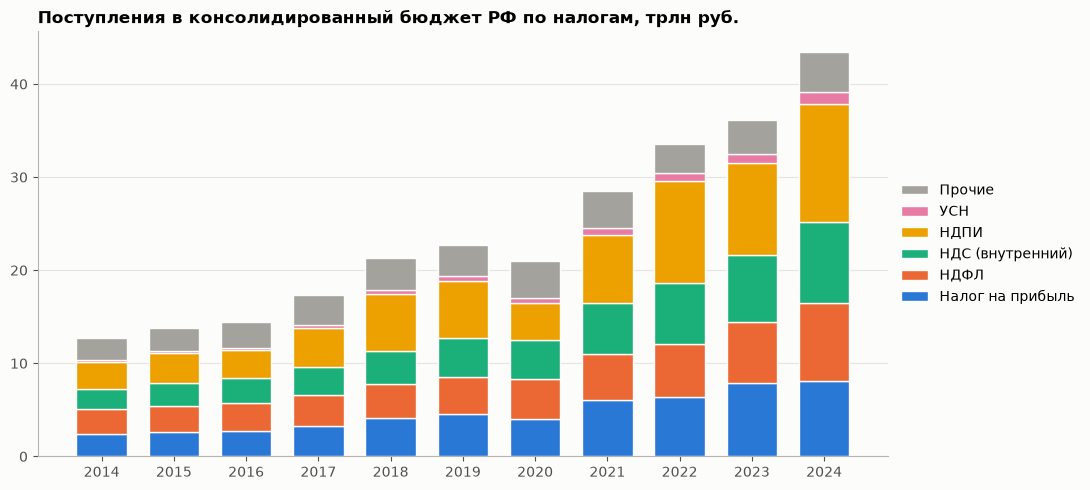

In [30]:
fig, ax = plt.subplots(figsize=(11, 5))
bottom = pd.Series(0.0, index=parts.index)
for color, name in zip(PALETTE[:len(names)] + [OTHER], parts.columns):
    ax.bar(parts.index, parts[name], bottom=bottom, width=0.7, color=color, label=name,
           edgecolor=SURFACE, linewidth=1)
    bottom += parts[name]
ax.set_title("Поступления в консолидированный бюджет РФ по налогам, трлн руб.")
ax.xaxis.set_major_locator(mticker.MultipleLocator(1))
ax.grid(axis="x", visible=False)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
fig.tight_layout()
plt.show()

### Обход иерархии рекурсивным запросом

Путь от итога «ВСЕГО» до каждой строки раздела «Поступления по видам экономической деятельности» (паспорт РФ, 2024 год). Иерархия воспроизводит файл как есть: добыча металлических руд стоит внутри «добычи топливно-энергетических полезных ископаемых».

In [31]:
q("""
    WITH RECURSIVE rows AS (
        SELECT r.row_code, r.parent_code, r.label
        FROM sheet_row r
        JOIN sheet s USING (year, territory_code, sheet_name)
        WHERE r.year = 2024 AND r.territory_code = 0 AND s.theme_code = 'revenue_by_activity'
          AND r.kind = 'indicator'
    ), tree AS (
        SELECT row_code, 0 AS depth, label AS path
        FROM rows
        WHERE parent_code IS NULL AND row_code = '701'
        UNION ALL
        SELECT r.row_code, t.depth + 1, t.path || ' / ' || r.label
        FROM rows r
        JOIN tree t ON r.parent_code = t.row_code
    )
    SELECT depth, row_code, path
    FROM tree
    WHERE path ILIKE '%добыча%'
    ORDER BY row_code
""")

,depth,row_code,path
0,1,704,ВСЕГО: / Добыча полезных ископаемых
1,2,705,ВСЕГО: / Добыча полезных ископаемых / добыча топливно-энергетических полезных ископаемых
2,3,706,ВСЕГО: / Добыча полезных ископаемых / добыча топливно-энергетических полезных ископаем...
3,3,707,ВСЕГО: / Добыча полезных ископаемых / добыча топливно-энергетических полезных ископаем...
4,3,708,ВСЕГО: / Добыча полезных ископаемых / добыча топливно-энергетических полезных ископаем...
5,3,709,ВСЕГО: / Добыча полезных ископаемых / добыча топливно-энергетических полезных ископаем...


## 9. Уровни бюджетной системы

В разделе 5 поступления разнесены по уровням бюджета: графа 3 — консолидированный бюджет РФ, 6 — федеральный бюджет, 9 — консолидированный бюджет субъекта, 12 — местные бюджеты. Доля бюджета субъекта в поступлениях за 2024 год:

In [32]:
levels = q("""
    SELECT territory,
           max(value) FILTER (WHERE col_no = 3) AS total_mln,
           max(value) FILTER (WHERE col_no = 6) AS federal_mln,
           max(value) FILTER (WHERE col_no = 9) AS regional_mln
    FROM v_value
    WHERE year = 2024 AND theme_code = 'revenue_by_budget' AND row_code = '501' AND territory_kind = 'region'
    GROUP BY territory
    ORDER BY territory
""")
levels["regional_share_pct"] = levels["regional_mln"] / levels["total_mln"] * 100
levels["check_mln"] = levels["total_mln"] - levels["federal_mln"] - levels["regional_mln"]
levels = levels.sort_values("regional_share_pct")
pd.concat([levels.head(5), levels.tail(5)])

,territory,total_mln,federal_mln,regional_mln,regional_share_pct,check_mln
75,Ханты-Мансийский АО-Югра,5 093 242.66,4 557 988.83,535 253.82,10.51,0.00
80,Ямало-Ненецкий АО,3 318 229.89,2 905 392.67,412 837.22,12.44,0.00
36,Оренбургская область,889 603.70,752 808.02,136 795.68,15.38,0.00
39,Пермский край,1 453 328.74,1 165 264.39,288 064.35,19.82,0.00
69,Томская область,413 862.96,330 137.04,83 725.92,20.23,0.00
11,Забайкальский край,81 386.98,-4 440.80,85 827.78,105.46,-0.00
58,Республика Хакасия,31 541.98,-3 163.25,34 705.23,110.03,0.00
28,Магаданская область,51 889.84,-7 072.03,58 961.87,113.63,-0.00
30,Мурманская область,66 090.92,-40 452.35,106 543.27,161.21,0.00
79,Чукотский автономный округ,17 954.17,-13 547.63,31 501.80,175.46,0.00


`check_mln` — итог минус федеральный и региональный бюджеты. Нулевое значение подтверждает, что графы 6 и 9 вместе составляют графу 3.

У части субъектов поступления в федеральный бюджет отрицательны: возмещение НДС превышает поступления. Тогда доля бюджета субъекта больше 100 %.

In [33]:
q("""
    SELECT territory, row_code, label, value AS federal_mln
    FROM v_value
    WHERE year = 2024 AND territory_code = 51 AND theme_code = 'revenue_by_budget' AND col_no = 6
      AND parent_code = '501' AND value < 0
    ORDER BY value
""")

,territory,row_code,label,federal_mln
0,Мурманская область,504,"Налог на добавленную стоимость на товары, реализуемые на территории РФ",-64 678.19
1,Мурманская область,506,"Акцизы по подакцизным товарам (продукции), производимым на территории РФ",-325.68


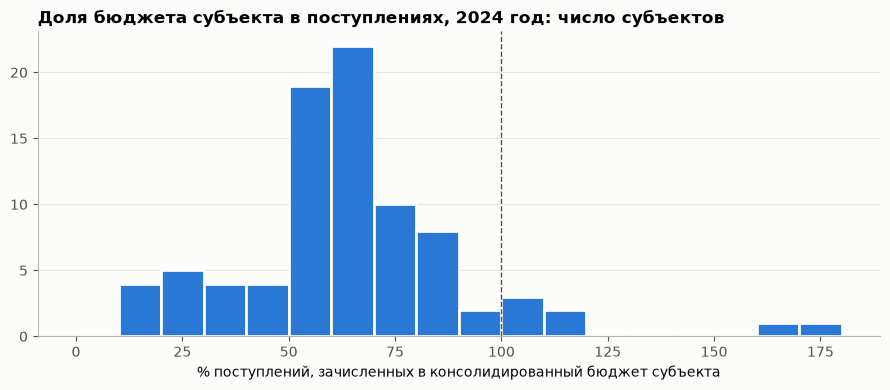

In [34]:
fig, ax = plt.subplots(figsize=(9, 4))
upper = int(levels["regional_share_pct"].max() // 10 + 2) * 10
ax.hist(levels["regional_share_pct"], bins=range(0, upper, 10), edgecolor=SURFACE, linewidth=2)
ax.axvline(100, color="#52514e", linewidth=1, linestyle="--")
ax.set_title("Доля бюджета субъекта в поступлениях, 2024 год: число субъектов")
ax.set_xlabel("% поступлений, зачисленных в консолидированный бюджет субъекта")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

## 10. Налоговая нагрузка

Налоговая нагрузка (поступления в % к ВРП) и ВРП на душу населения по субъектам за 2024 год. ВРП в млрд руб., делённый на численность в тыс. чел., даёт млн руб. на человека; умножаем на 1000, чтобы получить тыс. руб.

In [35]:
burden = q("""
    SELECT territory_code, territory,
           max(value) FILTER (WHERE theme_code = 'tax_burden' AND label_key = 'по администрируемым доходам')
               AS tax_burden_pct,
           max(value) FILTER (WHERE theme_code = 'socio_economic' AND row_code = '101') AS grp_bln,
           max(value) FILTER (WHERE theme_code = 'socio_economic' AND label_key = 'численность населения')
               AS population_ths
    FROM v_value
    WHERE year = 2024 AND territory_kind = 'region' AND col_no = 3
    GROUP BY ALL
    ORDER BY territory_code
""")
burden["grp_per_capita_ths"] = burden["grp_bln"] / burden["population_ths"] * 1e3
burden.sort_values("tax_burden_pct", ascending=False).head(10)

,territory_code,territory,tax_burden_pct,grp_bln,population_ths,grp_per_capita_ths
58,59,Пермский край,66.14,2 197.28,2 495.27,880.58
82,89,Ямало-Ненецкий АО,61.68,5 379.40,515.96,10 426.01
80,86,Ханты-Мансийский АО-Югра,59.03,8 628.90,1 759.39,4 904.50
55,56,Оренбургская область,50.43,1 764.00,1 828.66,964.64
62,63,Самарская область,50.39,2 646.49,3 127.84,846.11
17,18,Удмуртская Республика,46.70,1 102.90,1 434.56,768.81
69,70,Томская область,45.36,912.45,1 043.38,874.51
29,30,Астраханская область,35.82,777.72,946.43,821.74
15,16,Республика Татарстан,34.81,4 583.35,4 003.02,1 144.97
54,55,Омская область,33.70,1 056.60,1 818.09,581.16


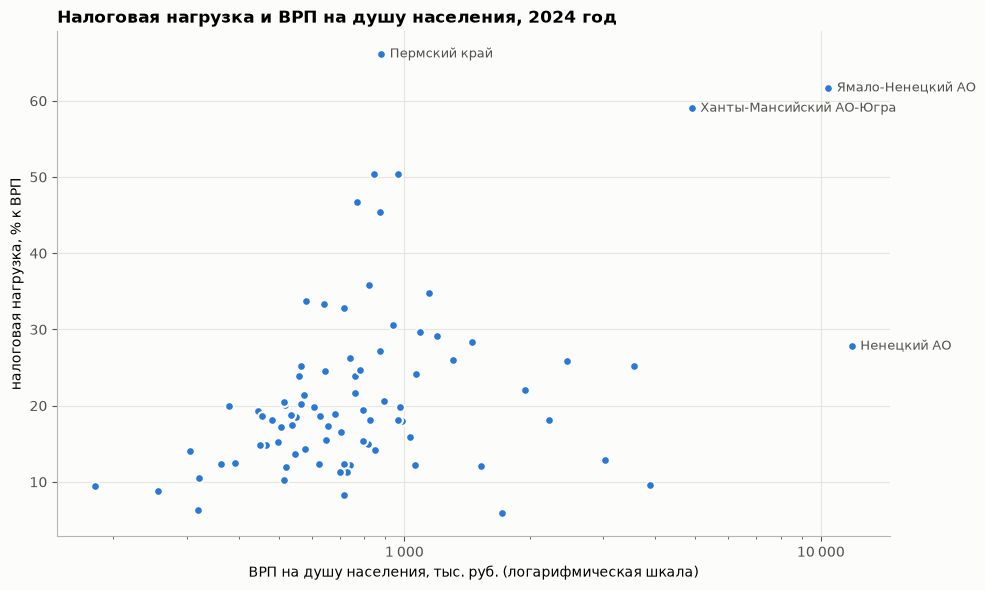

In [36]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(burden["grp_per_capita_ths"], burden["tax_burden_pct"], s=40, edgecolor=SURFACE, linewidth=1.5)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(thousands)
ax.set_title("Налоговая нагрузка и ВРП на душу населения, 2024 год")
ax.set_xlabel("ВРП на душу населения, тыс. руб. (логарифмическая шкала)")
ax.set_ylabel("налоговая нагрузка, % к ВРП")
labelled = pd.concat([burden.nlargest(3, "tax_burden_pct"), burden.nlargest(3, "grp_per_capita_ths")]).drop_duplicates()
for _, row in labelled.iterrows():
    ax.annotate(row["territory"], (row["grp_per_capita_ths"], row["tax_burden_pct"]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color="#52514e")
fig.tight_layout()
plt.show()

Налоговая нагрузка по видам деятельности (тема `tax_burden_by_activity`) с 2017 года дана за два года. Графы 2024 года:

In [37]:
q("""
    SELECT col_no, header, unit
    FROM v_column
    WHERE year = 2024 AND theme_code = 'tax_burden_by_activity'
    ORDER BY col_no
""")

,col_no,header,unit
0,3,"2023 год → Поступило в консолидированный бюджет РФ, млрд.руб",млрд. руб.
1,4,"2023 год → Оборот организаций, млрд.руб.",млрд. руб.
2,5,"2023 год → Налоговая нагрузка, %",%
3,6,"2024 год → Поступило в консолидированный бюджет РФ, млрд.руб",млрд. руб.
4,7,"2024 год → Оборот организаций, млрд.руб.",млрд. руб.
5,8,"2024 год → Налоговая нагрузка, %",%


## 11. Сопоставление показателей между годами

Код строки и имя листа зависят от шаблона года. Запрос по коду 1001 теряет 2014–2016 годы: тогда налоговая нагрузка стояла на листе «Раздел9» с кодом 901.

In [38]:
q("""
    SELECT year, sheet_name, row_code, value
    FROM v_value
    WHERE territory_code = 0 AND theme_code = 'tax_burden' AND row_code = '1001' AND col_no = 3
    ORDER BY year
""")

,year,sheet_name,row_code,value
0,2017,Раздел10,1001,20.13
1,2018,Раздел10,1001,20.53
2,2019,Раздел10,1001,26.76
3,2020,Раздел10,1001,22.16
4,2021,Раздел10,1001,30.41
5,2022,Раздел10,1001,27.71
6,2023,Раздел10,1001,25.72
7,2024,Раздел10,1001,21.73


### Способ 1: тема и `label_key`

`label_key` — наименование строки в нижнем регистре, без дат «по состоянию на», годов, единиц и пунктуации. По теме и `label_key` показатель находится во всех годах:

In [39]:
q("""
    SELECT year, sheet_name, row_code, label, value
    FROM v_value
    WHERE territory_code = 0 AND theme_code = 'tax_burden' AND label_key = 'по администрируемым доходам'
      AND col_no = 3
    ORDER BY year
""")

,year,sheet_name,row_code,label,value
0,2014,Раздел9,901,ПО АДМИНИСТРИРУЕМЫМ ДОХОДАМ,23.42
1,2015,Раздел9,901,ПО АДМИНИСТРИРУЕМЫМ ДОХОДАМ,23.41
2,2016,Раздел9,901,ПО АДМИНИСТРИРУЕМЫМ ДОХОДАМ,22.28
3,2017,Раздел10,1001,ПО АДМИНИСТРИРУЕМЫМ ДОХОДАМ,20.13
4,2018,Раздел10,1001,ПО АДМИНИСТРИРУЕМЫМ ДОХОДАМ,20.53
5,2019,Раздел10,1001,ПО АДМИНИСТРИРУЕМЫМ ДОХОДАМ,26.76
6,2020,Раздел10,1001,ПО АДМИНИСТРИРУЕМЫМ ДОХОДАМ,22.16
7,2021,Раздел10,1001,ПО АДМИНИСТРИРУЕМЫМ ДОХОДАМ,30.41
8,2022,Раздел10,1001,ПО АДМИНИСТРИРУЕМЫМ ДОХОДАМ,27.71
9,2023,Раздел10,1001,ПО АДМИНИСТРИРУЕМЫМ ДОХОДАМ,25.72


Численность населения: в 2014 году код строки 145, затем 151. Наименование содержит дату, а `label_key` — нет:

In [40]:
q("""
    SELECT year, row_code, label, label_key, value
    FROM v_value
    WHERE territory_code = 0 AND theme_code = 'socio_economic' AND label_key = 'численность населения' AND col_no = 3
    ORDER BY year
""")

,year,row_code,label,label_key,value
0,2014,145,ЧИСЛЕННОСТЬ НАСЕЛЕНИЯ НА 1 ЯНВАРЯ 2014 ГОДА (тыс.чел.),численность населения,146 267.30
1,2015,151,ЧИСЛЕННОСТЬ НАСЕЛЕНИЯ НА 1 ЯНВАРЯ 2016 ГОДА (тыс.чел.),численность населения,146 519.76
2,2016,151,ЧИСЛЕННОСТЬ НАСЕЛЕНИЯ НА 1 ЯНВАРЯ 2017 ГОДА (тыс.чел.),численность населения,146 804.40
3,2017,151,ЧИСЛЕННОСТЬ НАСЕЛЕНИЯ НА 1 ЯНВАРЯ 2018 ГОДА (тыс.чел.),численность населения,146 880.43
4,2018,151,ЧИСЛЕННОСТЬ НАСЕЛЕНИЯ НА 1 ЯНВАРЯ 2019 ГОДА (тыс.чел.),численность населения,146 780.72
5,2019,151,ЧИСЛЕННОСТЬ НАСЕЛЕНИЯ НА 1 ЯНВАРЯ 2020 ГОДА (тыс.чел.),численность населения,146 748.59
6,2020,151,ЧИСЛЕННОСТЬ НАСЕЛЕНИЯ НА 1 ЯНВАРЯ 2021 ГОДА (тыс.чел.),численность населения,146 171.02
7,2021,151,ЧИСЛЕННОСТЬ НАСЕЛЕНИЯ НА 1 ЯНВАРЯ 2022 ГОДА (тыс.чел.),численность населения,145 557.58
8,2022,151,ЧИСЛЕННОСТЬ НАСЕЛЕНИЯ НА 1 ЯНВАРЯ 2023 ГОДА (тыс.чел.),численность населения,146 447.42
9,2023,151,ЧИСЛЕННОСТЬ НАСЕЛЕНИЯ НА 1 ЯНВАРЯ 2024 ГОДА (тыс.чел.),численность населения,146 447.42


### Способ 2: показатели карты портала

Для 68 ключевых показателей карты портала таблица `map_indicator_source` указывает ячейку паспорта (лист, код строки, графу) по годам: сопоставлено 667 из 706 пар «год × показатель». `match_share` — доля территорий, у которых значение ячейки совпало со значением API. Функция `indicator_series()` собирает по ней ряд из паспортов:

In [41]:
def indicator_series(indicator_id: int) -> pd.DataFrame:
    """Ряд показателя карты портала по всем территориям, собранный из ячеек паспортов."""
    return q("""
        SELECT v.year, v.territory_code, v.territory, v.territory_kind, v.value * s.factor AS value,
               s.sheet_name, s.row_code, s.col_no, s.match_share
        FROM map_indicator_source s
        JOIN v_value v USING (year, sheet_name, row_code, col_no)
        WHERE s.indicator_id = $id
        ORDER BY v.year, v.territory_code
    """, id=indicator_id)


burden_series = indicator_series(57)  # «Всего по администрируемым доходам в КБ РФ», % к ВРП
burden_series.query("territory_code == 0")

,year,territory_code,territory,territory_kind,value,sheet_name,row_code,col_no,match_share
0,2014,0,РОССИЙСКАЯ ФЕДЕРАЦИЯ,country,23.42,Раздел9,901,3,1.00
92,2015,0,РОССИЙСКАЯ ФЕДЕРАЦИЯ,country,23.41,Раздел9,901,3,1.00
186,2016,0,РОССИЙСКАЯ ФЕДЕРАЦИЯ,country,22.28,Раздел9,901,3,1.00
280,2017,0,РОССИЙСКАЯ ФЕДЕРАЦИЯ,country,20.13,Раздел10,1001,3,1.00
374,2018,0,РОССИЙСКАЯ ФЕДЕРАЦИЯ,country,20.53,Раздел10,1001,3,1.00
468,2019,0,РОССИЙСКАЯ ФЕДЕРАЦИЯ,country,26.76,Раздел10,1001,3,1.00
562,2020,0,РОССИЙСКАЯ ФЕДЕРАЦИЯ,country,22.16,Раздел10,1001,3,1.00
656,2021,0,РОССИЙСКАЯ ФЕДЕРАЦИЯ,country,30.41,Раздел10,1001,3,1.00
750,2022,0,РОССИЙСКАЯ ФЕДЕРАЦИЯ,country,27.71,Раздел10,1001,3,1.00
844,2023,0,РОССИЙСКАЯ ФЕДЕРАЦИЯ,country,25.72,Раздел10,1001,3,1.00


Налоговая нагрузка в РФ и трёх субъектах. При четырёх рядах подписи стоят у концов линий, легенда дублирует их.

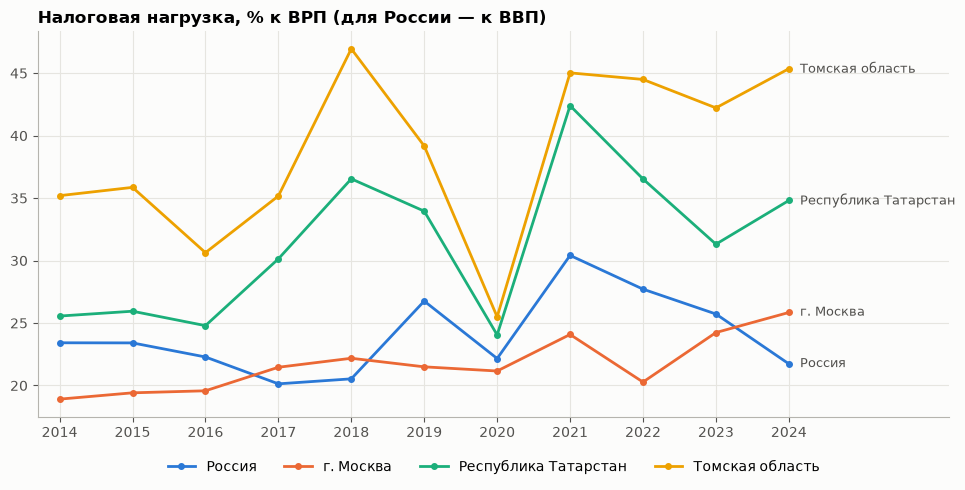

In [42]:
selected = {0: "Россия", 77: "г. Москва", 16: "Республика Татарстан", 70: "Томская область"}
wide = (burden_series[burden_series["territory_code"].isin(list(selected))]
        .pivot(index="year", columns="territory_code", values="value")[list(selected)]
        .rename(columns=selected))

fig, ax = plt.subplots(figsize=(10, 5))
for name in wide.columns:
    line, = ax.plot(wide.index, wide[name], marker="o", markersize=4, label=name)
    ax.annotate(name, (wide.index[-1], wide[name].iloc[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color="#52514e")
ax.set_title("Налоговая нагрузка, % к ВРП (для России — к ВВП)")
ax.set_xlim(wide.index[0] - 0.3, wide.index[-1] + 2.2)
ax.set_xticks(wide.index)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False, ncols=4)
fig.tight_layout()
plt.show()

Показатели карты, которые не всегда совпадают с одной ячейкой паспорта (портал считает их иначе, например суммой строк). Для них ряд по `map_indicator_source` приблизителен:

In [43]:
q("""
    SELECT s.indicator_id, any_value(m.name) AS name, min(s.match_share) AS min_match_share, count(*) AS years
    FROM map_indicator_source s
    JOIN map_indicator m USING (year, indicator_id)
    GROUP BY s.indicator_id
    HAVING min(s.match_share) < 0.95
    ORDER BY s.indicator_id
""")

,indicator_id,name,min_match_share,years
0,12,Налоговая база НДФЛ,0.00,10
1,15,Налоговая база по УСН,0.00,11
2,16,База для исчисления страховых взносов,0.00,8
3,22,Количество выездных налоговых проверок,0.09,11
4,32,Налоги на имущество,0.00,11
5,50,"Сельское, лесное хозяйство, охота, рыболовство, рыбоводство",0.01,9
6,62,"Сельское, лесное хозяйство, охота, рыболовство, рыбоводство",0.55,8


## 12. Субъекты, округа и РФ

Паспорта округов и РФ — готовые итоги. Их нельзя складывать с паспортами субъектов. Сумма поступлений по субъектам за 2024 год совпадает с суммой по округам, но не с паспортом РФ:

In [44]:
q("""
    SELECT territory_kind, count(*) AS passports, sum(value) AS revenue_mln
    FROM v_value
    WHERE year = 2024 AND theme_code = 'revenue_by_budget' AND row_code = '501' AND col_no = 3
    GROUP BY territory_kind
    ORDER BY revenue_mln DESC, territory_kind
""")

,territory_kind,passports,revenue_mln
0,country,1,43 471 515.48
1,federal_district,8,43 237 744.84
2,region,85,43 237 744.84


Сверка по округам: сумма субъектов округа против паспорта округа.

In [45]:
q("""
    WITH regions AS (
        SELECT t.federal_district_code AS territory_code, count(*) AS regions, sum(v.value) AS regions_sum_mln
        FROM v_value v
        JOIN territory t USING (territory_code)
        WHERE v.year = 2024 AND v.theme_code = 'revenue_by_budget' AND v.row_code = '501' AND v.col_no = 3
          AND v.territory_kind = 'region'
        GROUP BY ALL
    )
    SELECT v.territory, r.regions, r.regions_sum_mln, v.value AS district_mln, v.value - r.regions_sum_mln AS diff_mln
    FROM regions r
    JOIN v_value v USING (territory_code)
    WHERE v.year = 2024 AND v.theme_code = 'revenue_by_budget' AND v.row_code = '501' AND v.col_no = 3
    ORDER BY v.territory_code
""")

,territory,regions,regions_sum_mln,district_mln,diff_mln
0,ЦЕНТРАЛЬНЫЙ ФЕДЕРАЛЬНЫЙ ОКРУГ,18,13 231 612.02,13 231 612.02,0.00
1,СЕВЕРО-ЗАПАДНЫЙ ФЕДЕРАЛЬНЫЙ ОКРУГ,11,4 174 713.40,4 174 713.40,0.00
2,ЮЖНЫЙ ФЕДЕРАЛЬНЫЙ ОКРУГ,8,2 004 300.47,2 004 300.47,0.00
3,ПРИВОЛЖСКИЙ ФЕДЕРАЛЬНЫЙ ОКРУГ,14,7 906 480.00,7 906 480.00,-0.00
4,УРАЛЬСКИЙ ФЕДЕРАЛЬНЫЙ ОКРУГ,6,10 422 800.82,10 422 800.82,0.00
5,СИБИРСКИЙ ФЕДЕРАЛЬНЫЙ ОКРУГ,10,3 394 165.36,3 394 165.36,0.00
6,ДАЛЬНЕВОСТОЧНЫЙ ФЕДЕРАЛЬНЫЙ ОКРУГ,11,1 709 898.27,1 709 898.27,0.00
7,СЕВЕРО-КАВКАЗСКИЙ ФЕДЕРАЛЬНЫЙ ОКРУГ,7,393 774.50,393 774.50,0.00


Значение по России берите из паспорта РФ, а не суммируйте субъекты. Относительные показатели (проценты, нагрузка, значения на душу населения) складывать нельзя вовсе.

## 13. Нечисловые значения и единицы измерения

Текстовые ячейки: `X` — «не заполняется», `-` — «нет данных». В базе у них `value IS NULL`, а текст лежит в `value_text`. Пустые ячейки не хранятся.

In [46]:
q("""
    SELECT value_text, count(*) AS cells, count(DISTINCT year) AS years
    FROM value
    WHERE value_text IS NOT NULL
    GROUP BY value_text
    ORDER BY cells DESC
""")

,value_text,cells,years
0,X,168160,11
1,-,942,3


Например, НДС на товары, реализуемые на территории РФ, в бюджет субъекта не зачисляется:

In [47]:
q("""
    SELECT col_no, column_header, value, value_text
    FROM v_value
    WHERE year = 2024 AND territory_code = 70 AND theme_code = 'revenue_by_budget' AND row_code = '504'
    ORDER BY col_no
""")

,col_no,column_header,value,value_text
0,3,Поступило в консолидированный бюджет Российской Федерации → Всего,89 382.02,NaN
1,4,Поступило в консолидированный бюджет Российской Федерации → В % к предыдущему периоду,119.30,NaN
2,5,Поступило в консолидированный бюджет Российской Федерации → Удельный вес (%),21.60,NaN
3,6,в том числе: → В федеральный бюджет → Всего,89 382.02,NaN
4,7,в том числе: → В федеральный бюджет → В % к предыдущему периоду,119.30,NaN
5,8,в том числе: → В федеральный бюджет → Удельный вес (%),27.07,NaN
6,9,в том числе: → В консолидированный бюджет субъекта РФ → Всего,NaN,X
7,10,в том числе: → В консолидированный бюджет субъекта РФ → В % к предыдущему периоду,NaN,X
8,11,в том числе: → В консолидированный бюджет субъекта РФ → Удельный вес (%),NaN,X
9,12,в том числе: → из него: → В местный бюджет → Всего,NaN,X


`X` и `-` не равны нулю. `count(value)` и `avg(value)` пропускают такие ячейки сами. Замена `coalesce(value, 0)` превращает «не заполняется» в ноль и искажает средние.

Единица значения (`value.unit`) выбирается из шапки графы, наименования строки, надписи над таблицей или по умолчанию для темы. Источник записан в `unit_source`:

In [48]:
q("""
    SELECT unit_source, unit, count(*) AS cells
    FROM value
    GROUP BY ALL
    ORDER BY cells DESC, unit_source, unit
    LIMIT 15
""")

,unit_source,unit,cells
0,column,%,624349
1,theme_default,млн. руб.,533090
2,section,млн. руб.,261288
3,column,млн. руб.,125000
4,row,млн. руб.,89949
5,row,ед.,48867
6,row,%,45963
7,column,млрд. руб.,41331
8,row,млрд. руб.,17081
9,section,млрд. руб.,6189


Внутри одной строки графы бывают в разных единицах: сумма в «млн. руб.», а рядом «В % к предыдущему периоду» и «Удельный вес (%)».

In [49]:
q("""
    SELECT col_no, column_header, value, unit, unit_source
    FROM v_value
    WHERE year = 2024 AND territory_code = 70 AND theme_code = 'revenue_by_budget' AND row_code = '501'
    ORDER BY col_no
""")

,col_no,column_header,value,unit,unit_source
0,3,Поступило в консолидированный бюджет Российской Федерации → Всего,413 862.96,млн. руб.,theme_default
1,4,Поступило в консолидированный бюджет Российской Федерации → В % к предыдущему периоду,121.07,%,column
2,5,Поступило в консолидированный бюджет Российской Федерации → Удельный вес (%),100.00,%,column
3,6,в том числе: → В федеральный бюджет → Всего,330 137.04,млн. руб.,theme_default
4,7,в том числе: → В федеральный бюджет → В % к предыдущему периоду,124.99,%,column
5,8,в том числе: → В федеральный бюджет → Удельный вес (%),100.00,%,column
6,9,в том числе: → В консолидированный бюджет субъекта РФ → Всего,83 725.92,млн. руб.,theme_default
7,10,в том числе: → В консолидированный бюджет субъекта РФ → В % к предыдущему периоду,107.77,%,column
8,11,в том числе: → В консолидированный бюджет субъекта РФ → Удельный вес (%),100.00,%,column
9,12,в том числе: → из него: → В местный бюджет → Всего,17 190.17,млн. руб.,theme_default


## 14. Показатели карты портала

Кроме архивов, портал отдаёт через JSON API ключевые показатели для карты: справочник `map_indicator` и значения `map_indicator_value`. Значения в API уже умножены на `scale` (`млн`, `млрд`, `тыс`). Показатели 2024 года:

In [50]:
q("""
    SELECT theme_no, indicator_id, name, scale, unit_value, start_year, end_year
    FROM map_indicator
    WHERE year = 2024
    ORDER BY theme_no, indicator_id
""")

,theme_no,indicator_id,name,scale,unit_value,start_year,end_year
0,1,1,Валовой внутренний/региональный продукт,млрд,₽,2014,<NA>
1,1,2,Индекс промышленного производства,NaN,%,2014,<NA>
2,1,3,Оборот розничной торговли,млрд,₽,2014,<NA>
3,1,4,Сальдированный финансовый результат (прибыль минус убыток),млрд,₽,2014,<NA>
4,1,5,Индекс потребительских цен (декабрь к декабрю),NaN,%,2014,<NA>
5,1,6,Среднемесячная начисленная заработная плата,NaN,₽,2014,<NA>
6,1,7,Численность рабочей силы (экономически активного населения),тыс,чел.,2014,<NA>
7,1,8,Количество муниципальных образований,NaN,ед.,2014,<NA>
8,1,9,Численность населения,тыс,чел.,2014,<NA>
9,2,10,Налоговая база для исчисления налога на прибыль организаций,млн,₽,2014,<NA>


НДФЛ (`indicator_id = 29`) по федеральным округам: значение и изменение к прошлому году (`difference`).

In [51]:
q("""
    SELECT t.name, m.value, m.difference, m.heat_map_type
    FROM map_indicator_value m
    JOIN territory t USING (territory_code)
    WHERE m.year = 2024 AND m.indicator_id = 29 AND t.kind = 'federal_district'
    ORDER BY m.value DESC
""")

,name,value,difference,heat_map_type
0,ЦЕНТРАЛЬНЫЙ ФЕДЕРАЛЬНЫЙ ОКРУГ,3 597 196.16,128.97,4
1,ПРИВОЛЖСКИЙ ФЕДЕРАЛЬНЫЙ ОКРУГ,1 026 590.28,128.74,4
2,СЕВЕРО-ЗАПАДНЫЙ ФЕДЕРАЛЬНЫЙ ОКРУГ,1 017 429.82,129.69,4
3,УРАЛЬСКИЙ ФЕДЕРАЛЬНЫЙ ОКРУГ,721 618.14,123.65,4
4,СИБИРСКИЙ ФЕДЕРАЛЬНЫЙ ОКРУГ,704 216.02,123.31,4
5,ЮЖНЫЙ ФЕДЕРАЛЬНЫЙ ОКРУГ,517 136.87,123.78,4
6,ДАЛЬНЕВОСТОЧНЫЙ ФЕДЕРАЛЬНЫЙ ОКРУГ,496 155.73,120.52,4
7,СЕВЕРО-КАВКАЗСКИЙ ФЕДЕРАЛЬНЫЙ ОКРУГ,139 252.16,123.44,4


Сверка API с паспортами: значение карты против ячейки паспорта, умноженной на `factor`, по всем годам и территориям.

In [52]:
q("""
    SELECT s.indicator_id, any_value(m.name) AS name,
           count(*) AS values,
           count(*) FILTER (WHERE abs(mv.value - v.value * s.factor) <= 1e-6 * abs(mv.value) + 0.001) AS equal
    FROM map_indicator_source s
    JOIN map_indicator m USING (year, indicator_id)
    JOIN map_indicator_value mv USING (year, indicator_id)
    JOIN v_value v
      ON v.year = s.year AND v.territory_code = mv.territory_code AND v.sheet_name = s.sheet_name
     AND v.row_code = s.row_code AND v.col_no = s.col_no
    WHERE s.indicator_id IN (1, 9, 27, 29, 57)
    GROUP BY s.indicator_id
    ORDER BY s.indicator_id
""")

,indicator_id,name,values,equal
0,1,Валовой внутренний/региональный продукт,1032,1032
1,9,Численность населения,1032,1032
2,27,Всего поступило по администрируемым доходам,1032,1032
3,29,НДФЛ,1032,1032
4,57,Всего по администрируемым доходам в КБ РФ,1032,1032


## 15. Пересмотры

ФНС может заменить уже опубликованный паспорт. Прежние загрузки хранятся в `data/raw/snapshots/<дата>/`, а при сборке базы изменения выводятся в `passport_revision` (какой файл изменился) и `value_revision` (какие ячейки).

In [53]:
q("SELECT * FROM passport_revision")

,snapshot,year,territory_code,old_file_sha256,new_file_sha256,changed_cells
0,2025-03-20,2023,0,bb24047dee2638acdfca3ab368acc08fc40d309055951ae7cfc86736f32bcf10,b9270e27e63a91a10eec200aa55660815094fe09c315eb23253d65827ba6e8d3,4


In [54]:
q("""
    SELECT rv.snapshot, rv.year, t.name AS territory, rv.sheet_name, rv.row_code, r.label, rv.col_no,
           rv.old_value, rv.new_value
    FROM value_revision rv
    JOIN territory t USING (territory_code)
    LEFT JOIN sheet_row r USING (year, territory_code, sheet_name, row_no)
    ORDER BY rv.year, rv.territory_code, rv.row_no, rv.col_no
""")

,snapshot,year,territory,sheet_name,row_code,label,col_no,old_value,new_value
0,2025-03-20,2023,РОССИЙСКАЯ ФЕДЕРАЦИЯ,Раздел1,101,ВАЛОВОЙ ВНУТРЕННИЙ ПРОДУКТ (млрд. руб.),3,140 670.82,176 413.59
1,2025-03-20,2023,РОССИЙСКАЯ ФЕДЕРАЦИЯ,Раздел1,101,ВАЛОВОЙ ВНУТРЕННИЙ ПРОДУКТ (млрд. руб.),4,115.12,112.41
2,2025-03-20,2023,РОССИЙСКАЯ ФЕДЕРАЦИЯ,Раздел1,102,ИНДЕКС ФИЗИЧЕСКОГО ОБЪЕМА ВВП (%),3,100.30,104.08
3,2025-03-20,2023,РОССИЙСКАЯ ФЕДЕРАЦИЯ,Раздел1,103,ИНДЕКС ПРОМЫШЛЕННОГО ПРОИЗВОДСТВА (%),3,103.50,104.30


В паспорте РФ за 2023 год пересмотрены ВВП и индексы физического объёма ВВП и промышленного производства. Значения в остальных таблицах — по последней загрузке.

## 16. Parquet без DuckDB

Файлы `data/parquet/*.parquet` читаются любым инструментом с поддержкой Parquet: pandas, Polars, R (`arrow`), Spark. Пример на pandas: ВРП Томской области за 2024 год без SQL. Фильтры `filters` применяются при чтении, поэтому в память попадает только нужная часть таблицы.

In [55]:
keys = ["year", "territory_code", "sheet_name"]
value = pd.read_parquet(PARQUET / "value.parquet", filters=[("year", "==", 2024), ("territory_code", "==", 70)])
sheet = pd.read_parquet(PARQUET / "sheet.parquet", columns=[*keys, "theme_code"])
rows = pd.read_parquet(PARQUET / "sheet_row.parquet", columns=[*keys, "row_no", "label"],
                       filters=[("year", "==", 2024), ("territory_code", "==", 70)])

grp = (value.merge(sheet, on=keys)
            .merge(rows, on=[*keys, "row_no"])
            .query("theme_code == 'socio_economic' and row_code == '101'"))
grp[["year", "sheet_name", "row_code", "label", "col_no", "value", "unit"]]

,year,sheet_name,row_code,label,col_no,value,unit
0,2024,Раздел1,101,ВАЛОВОЙ РЕГИОНАЛЬНЫЙ ПРОДУКТ (по состоянию на 01.01.2024) (млрд. руб.),3,912.45,млрд. руб.
1,2024,Раздел1,101,ВАЛОВОЙ РЕГИОНАЛЬНЫЙ ПРОДУКТ (по состоянию на 01.01.2024) (млрд. руб.),4,112.21,%


## 17. Выгрузка результатов

Поступления по субъектам за все годы в широком формате (субъект × год, млрд руб.). `PIVOT` выполняется в DuckDB:

In [56]:
revenue_wide = q("""
    PIVOT (
        SELECT territory, year, round(value / 1e3, 1) AS revenue_bln
        FROM v_value
        WHERE theme_code = 'revenue_by_budget' AND row_code = '501' AND col_no = 3 AND territory_kind = 'region'
    )
    ON year
    USING first(revenue_bln)
    ORDER BY territory
""")
revenue_wide.head(10)

,territory,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Алтайский край,60.80,63.40,73.10,79.50,83.90,91.10,94.90,121.40,131.00,153.10,185.70
1,Амурская область,38.30,39.10,41.30,23.00,29.80,19.70,24.10,23.30,49.60,61.90,97.20
2,Архангельская область,48.80,63.20,53.00,69.00,73.90,91.20,74.80,87.00,110.80,102.60,117.30
3,Астраханская область,56.70,68.30,85.70,114.90,160.70,177.80,134.90,191.70,253.20,245.10,278.60
4,Белгородская область,64.20,70.10,68.50,91.30,113.80,123.90,115.80,215.70,192.90,232.40,276.40
5,Брянская область,31.80,34.10,50.40,44.00,51.70,53.90,51.60,69.20,85.60,106.00,115.70
6,Владимирская область,54.90,58.50,66.40,70.80,80.00,84.70,90.40,115.90,125.60,150.40,168.70
7,Волгоградская область,109.80,119.00,131.80,160.20,188.40,166.30,223.20,257.50,286.60,302.20,348.60
8,Вологодская область,54.50,55.90,60.50,70.70,86.20,87.60,77.50,134.90,146.90,230.20,196.50
9,Воронежская область,75.90,79.10,88.40,98.00,119.20,128.30,143.60,170.20,192.60,225.90,259.50


Сохранить результат в файл:

```python
revenue_wide.to_csv("revenue_by_region.csv", index=False)       # CSV через pandas
revenue_wide.to_excel("revenue_by_region.xlsx", index=False)    # Excel (нужен openpyxl)

# выгрузка средствами DuckDB, без pandas
con.execute("""
    COPY (SELECT * FROM v_value WHERE year = 2024 AND territory_kind = 'region')
    TO 'values_2024.parquet' (FORMAT parquet)
""")
```

Перед публикацией результатов проверьте список «Как не ошибиться» в [database.md](database.md#как-не-ошибиться).